# Prática do Card 11 - escorpiões

Reproduzi os conteúdos trabalhados durante as aulas, aplicando os conceitos ao tema do meu projeto, que consiste em um aplicativo capaz de identificar escorpiões por meio de fotografias.

A tabela de espécies foi elaborada por mim, e os valores das medidas foram definidos de forma fictícia pois eu não sei exatamente, apenas para fins de treinamento e aplicação dos métodos portanto não representam dados biológicos reais.

Ao longo do projeto, foram abordados os conteúdos KNN, PCA, aprendizado por reforço, validação cruzada K-Fold, identificação de outliers e limpeza de dados inconsistentes.

## More Data Mining and Machine Learning Techniques

In [1]:
import numpy as np
import pandas as pd

# aqui eu monto minha propria tabela de especies
especies = ['Tityus serrulatus', 'Tityus bahiensis', 'Tityus stigmurus',
            'Tityus obscurus', 'Bothriurus bonariensis', 'Rhopalurus rochai']

# as colunas sao comprimento em mm grossura da cauda grossura da pinca tom claro e se e perigoso
atributos = np.array([
    [70, 0.9, 0.3, 0.9, 1],
    [65, 0.8, 0.5, 0.2, 1],
    [68, 0.9, 0.3, 0.8, 1],
    [85, 0.7, 0.4, 0.1, 1],
    [45, 0.3, 0.8, 0.3, 0],
    [60, 0.6, 0.5, 0.7, 0],
])

colunas = ['comprimento_mm', 'grossura_cauda', 'grossura_pinca', 'tom_claro', 'perigoso']
escorpioes = pd.DataFrame(atributos, index=especies, columns=colunas)
escorpioes

,comprimento_mm,grossura_cauda,grossura_pinca,tom_claro,perigoso
Tityus serrulatus,70.0,0.9,0.3,0.9,1.0
Tityus bahiensis,65.0,0.8,0.5,0.2,1.0
Tityus stigmurus,68.0,0.9,0.3,0.8,1.0
Tityus obscurus,85.0,0.7,0.4,0.1,1.0
Bothriurus bonariensis,45.0,0.3,0.8,0.3,0.0
Rhopalurus rochai,60.0,0.6,0.5,0.7,0.0


In [2]:
from scipy import spatial

# tiro a coluna perigoso porque ela e a resposta e nao pode entrar na conta
medidas = escorpioes[['comprimento_mm', 'grossura_cauda', 'grossura_pinca', 'tom_claro']].values

# normalizo tudo entre 0 e 1 senao o comprimento domina por ser um numero grande
medidas_norm = (medidas - medidas.min(axis=0)) / (medidas.max(axis=0) - medidas.min(axis=0))

def distancia(i, j):
    return spatial.distance.cosine(medidas_norm[i], medidas_norm[j])

print(distancia(0, 2)) # dois Tityus que se parecem bastante
print(distancia(0, 4)) # Tityus contra Bothriurus que e de outra familia

0.001889102589083369
0.8431372549019608


In [3]:
import operator

# mesma ideia do KNN da aula so que agora os vizinhos sao especies
def getVizinhos(indice, K):
    distancias = []
    for i in range(len(medidas_norm)):
        if i != indice:
            distancias.append((i, distancia(indice, i)))
    distancias.sort(key=operator.itemgetter(1))
    return [d[0] for d in distancias[:K]]

K = 3
alvo = 0
vizinhos = getVizinhos(alvo, K)

print("quem mais parece com o " + especies[alvo])
for v in vizinhos:
    print("  " + especies[v] + " distancia " + str(round(distancia(alvo, v), 4)))

# deixo os vizinhos votarem se o alvo e perigoso
voto = np.mean([escorpioes['perigoso'].values[v] for v in vizinhos])
print("palpite dos vizinhos " + str(voto))
print("resposta certa " + str(escorpioes['perigoso'].values[alvo]))

quem mais parece com o Tityus serrulatus
  Tityus stigmurus distancia 0.0019
  Rhopalurus rochai distancia 0.0901
  Tityus bahiensis distancia 0.2234
palpite dos vizinhos 0.6666666666666666
resposta certa 1.0


[0.67067228 0.29292968]
0.9636019588190383


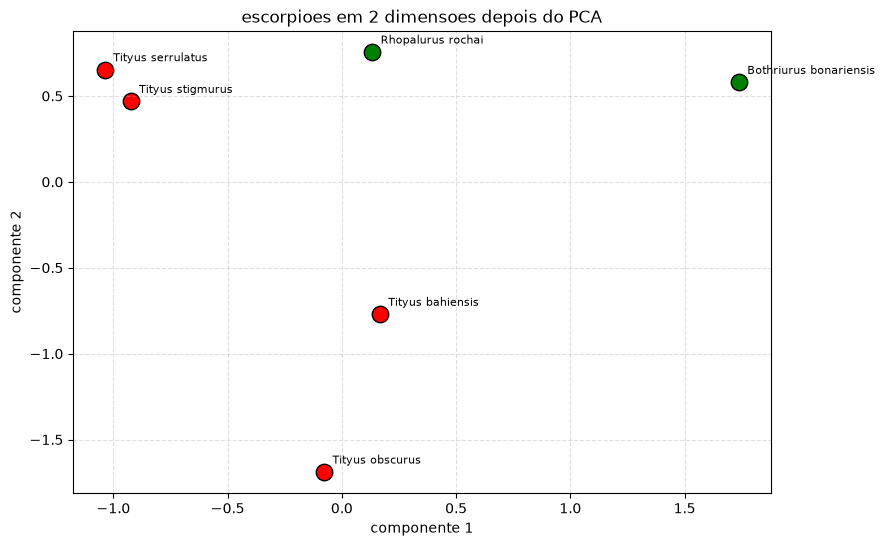

In [4]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# espremo as 4 medidas em 2 pra conseguir desenhar as especies num grafico
pca = PCA(n_components=2, whiten=True).fit(medidas_norm)
pontos = pca.transform(medidas_norm)

print(pca.explained_variance_ratio_)
print(sum(pca.explained_variance_ratio_)) # quanto sobrou depois de espremer

plt.figure(figsize=(9, 6))
for i, nome in enumerate(especies):
    # pinto de vermelho quem e perigoso e de verde quem nao e
    cor = 'red' if escorpioes['perigoso'].values[i] == 1 else 'green'
    plt.scatter(pontos[i, 0], pontos[i, 1], c=cor, s=140, edgecolors='black')
    plt.annotate(nome, (pontos[i, 0], pontos[i, 1]), fontsize=8,
                 xytext=(6, 6), textcoords='offset points')

plt.title("escorpioes em 2 dimensoes depois do PCA")
plt.xlabel("componente 1")
plt.ylabel("componente 2")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Aqui eu não usei o Taxi do curso, Montei um ambiente meu

In [5]:
import random

# meu ambiente e uma grade 4 por 4
# a casa 0 e onde o agente comeca e a casa 15 e onde esta o escorpiao
# as casas 5 e 9 sao pedra e ele toma penalidade se tentar passar
LINHAS, COLUNAS = 4, 4
DESTINO = 15
PEDRAS = [5, 9]
ACOES = {0: -COLUNAS, 1: COLUNAS, 2: -1, 3: 1} # cima baixo esquerda direita

def anda(estado, acao):
    linha, coluna = divmod(estado, COLUNAS)
    # se tentar sair do mapa ele fica parado e perde ponto
    if acao == 0 and linha == 0: return estado, -5
    if acao == 1 and linha == LINHAS - 1: return estado, -5
    if acao == 2 and coluna == 0: return estado, -5
    if acao == 3 and coluna == COLUNAS - 1: return estado, -5
    novo = estado + ACOES[acao]
    if novo in PEDRAS: return estado, -10 # bateu na pedra
    if novo == DESTINO: return novo, 20   # achou o escorpiao
    return novo, -1                       # andou normal e gastou um passo

In [6]:
random.seed(1234)

# mesma tabela da aula so que agora sao 16 casas e 4 acoes
q_table = np.zeros([LINHAS * COLUNAS, len(ACOES)])

learning_rate = 0.1
discount_factor = 0.9
exploration = 0.2
epochs = 5000

for rodada in range(epochs):
    estado = 0
    passos = 0
    while estado != DESTINO and passos < 100:
        if random.uniform(0, 1) < exploration:
            acao = random.randint(0, len(ACOES) - 1) # tenta algo novo
        else:
            acao = np.argmax(q_table[estado])        # usa o que ja deu certo

        novo_estado, recompensa = anda(estado, acao)

        prev_q = q_table[estado, acao]
        next_max_q = np.max(q_table[novo_estado])
        # a mesma equacao de Bellman da aula
        q_table[estado, acao] = (1 - learning_rate) * prev_q + learning_rate * (
            recompensa + discount_factor * next_max_q
        )

        estado = novo_estado
        passos += 1

print(q_table[0]) # a nota das 4 acoes na casa inicial

[1.94323    7.71469996 1.94323    7.7147    ]


In [7]:
nomes = {0: 'cima', 1: 'baixo', 2: 'esquerda', 3: 'direita'}

# agora eu so sigo a maior nota de cada casa pra ver o caminho que ele aprendeu
estado = 0
caminho = [estado]
while estado != DESTINO and len(caminho) < 20:
    acao = int(np.argmax(q_table[estado]))
    print("casa " + str(estado) + " vai pra " + nomes[acao])
    estado, _ = anda(estado, acao)
    caminho.append(estado)

print("caminho final " + str(caminho))

casa 0 vai pra direita
casa 1 vai pra direita
casa 2 vai pra baixo
casa 6 vai pra direita
casa 7 vai pra baixo
casa 11 vai pra baixo
caminho final [0, 1, 2, 6, 7, 11, 15]


## Dealing with Real-World Data

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import svm

# com 6 linhas so nao da pra treinar nada
# entao eu gero 20 individuos em volta da medida de cada especie
np.random.seed(42)
X = []
y = []
for i in range(len(especies)):
    amostras = np.random.normal(medidas_norm[i], 0.20, size=(20, medidas_norm.shape[1]))
    X.append(amostras)
    y += [int(escorpioes['perigoso'].values[i])] * 20

X = np.vstack(X)
y = np.array(y)
print(X.shape, y.shape)

# separo 40 por cento pro teste igual a aula
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)

clf = svm.SVC(kernel='linear', C=1).fit(X_train, y_train)
print("teste simples " + str(clf.score(X_test, y_test)))

(120, 4) (120,)
teste simples 0.9791666666666666


In [9]:
# agora o K-Fold que testa 5 vezes trocando o pedaco que fica de fora
scores = cross_val_score(clf, X, y, cv=5)
print(scores)
print(scores.mean()) # repare que a media deu menor que o teste simples la de cima
# ou seja aquele 0.97 foi sorte da divisao e esse numero aqui e o real

[1.         0.91666667 0.95833333 0.875      0.875     ]
0.925


media com o erro 66.69
media limpa 64.78
joguei fora 1 registro


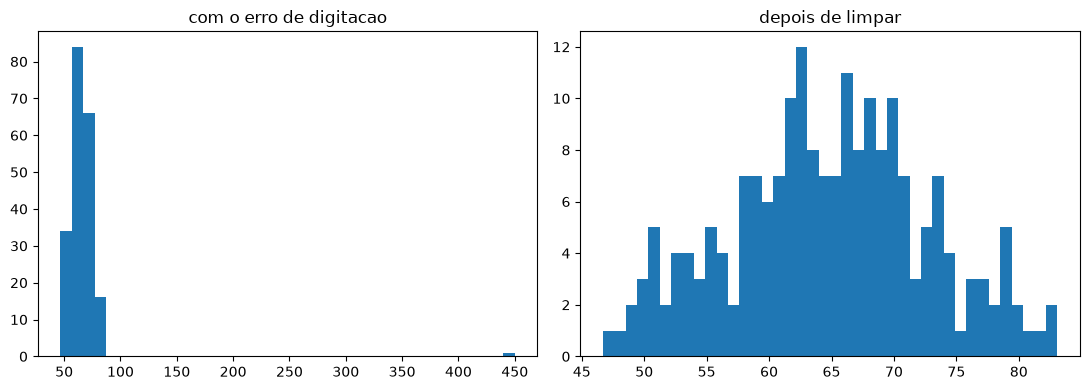

In [10]:
# aqui eu simulo alguem digitando o tamanho errado no cadastro do app
np.random.seed(7)
tamanhos = np.random.normal(65, 8, 200)
tamanhos = np.append(tamanhos, [450]) # digitaram 450 mm em vez de 45

print("media com o erro " + str(round(np.mean(tamanhos), 2)))

def reject_outliers(data):
    u = np.median(data) # mediana porque ela nao se abala com o valor doido
    s = np.std(data)
    return [e for e in data if (u - 2 * s < e < u + 2 * s)]

limpos = reject_outliers(tamanhos)
print("media limpa " + str(round(np.mean(limpos), 2)))
print("joguei fora " + str(len(tamanhos) - len(limpos)) + " registro")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.hist(tamanhos, 40)
plt.title("com o erro de digitacao")
plt.subplot(1, 2, 2)
plt.hist(limpos, 40)
plt.title("depois de limpar")
plt.tight_layout()
plt.show()

In [11]:
import re

# aqui e a mesma ideia do log do curso so que o arquivo sujo e do meu app
registros = [
    "2026-03-01;Tityus serrulatus;foto_ok",
    "2026-03-01;tityus serrulatus ;foto_ok",
    "2026-03-02;Bothriurus bonariensis;foto_ok",
    "2026-03-02;;foto_ruim",
    "lixo",
    "2026-03-03;Tityus bahiensis;foto_ok",
    "2026-03-03;TITYUS SERRULATUS;foto_ok",
    "2026-03-04;Rhopalurus rochai;foto_ok",
    "2026-03-04;Tityus serrulatus;foto_ruim",
]

# o padrao exige data especie e situacao da foto senao a linha nao serve
padrao = re.compile(r"^(?P<data>\d{4}-\d{2}-\d{2});(?P<especie>[^;]+);(?P<foto>\w+)$")

contagem = {}
descartados = 0

for linha in registros:
    achou = padrao.match(linha)
    if not achou:
        descartados += 1
        continue
    campos = achou.groupdict()
    # arrumo caixa alta e espaco sobrando senao a mesma especie vira tres especies
    nome = campos['especie'].strip().title()
    if campos['foto'] != 'foto_ok':
        descartados += 1
        continue
    contagem[nome] = contagem.get(nome, 0) + 1

print("descartei " + str(descartados) + " registro")
for nome in sorted(contagem, key=contagem.get, reverse=True):
    print(nome + ": " + str(contagem[nome]))

descartei 3 registro
Tityus Serrulatus: 3
Bothriurus Bonariensis: 1
Tityus Bahiensis: 1
Rhopalurus Rochai: 1
